ML-Labor SS26

1) train_data hochladen

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [3]:
train_data = pd.read_csv('train.csv', sep=';')

train_data.head()

,transactionId,basket,customerType,totalAmount,returnLabel
0,9534310106,"[4, 3, 4]",new,252.0,1
1,7202594767,"[4, 2, 0, 2, 5]",existing,70.0,0
2,2737331698,[5],existing,84.0,0
3,4868011733,"[1, 4, 2, 4]",existing,116.0,0
4,7622406570,"[2, 5, 3, 2, 3, 2, 0]",existing,378.0,0


2) EDV

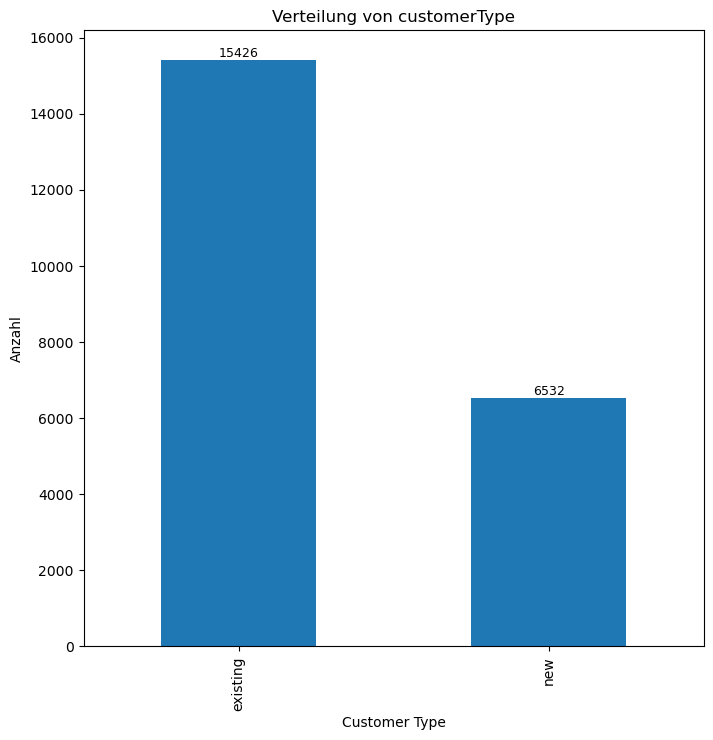

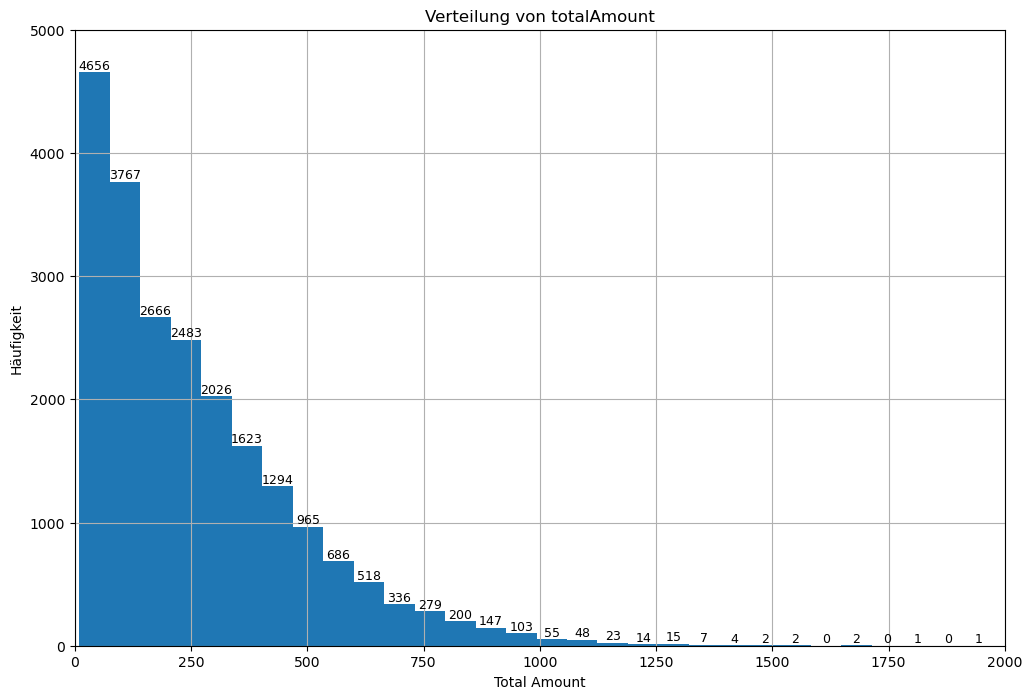

In [8]:
plt.figure(figsize=(8, 8))
ax = train_data['customerType'].value_counts().plot(kind='bar')
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
plt.title('Verteilung von customerType')
plt.xlabel('Customer Type')
plt.ylabel('Anzahl')
plt.show()


plt.figure(figsize=(12, 8))
ax = train_data['totalAmount'].hist(bins=30)
plt.ylim(0, 5000)
plt.xlim(0, 2000)
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
plt.title('Verteilung von totalAmount')
plt.xlabel('Total Amount')
plt.ylabel('Häufigkeit')
plt.show()

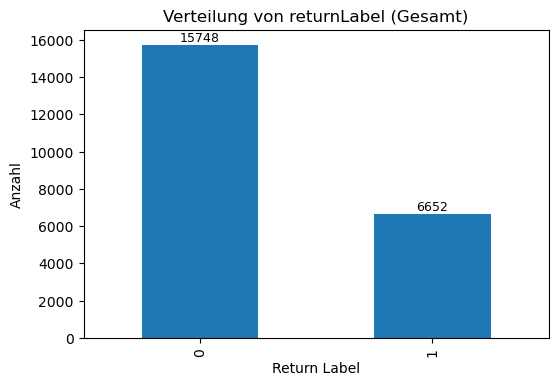

In [4]:
plt.figure(figsize=(6, 4))
ax = train_data['returnLabel'].value_counts().plot(kind='bar')
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
plt.title('Verteilung von returnLabel (Gesamt)')
plt.xlabel('Return Label')
plt.ylabel('Anzahl')
plt.show()

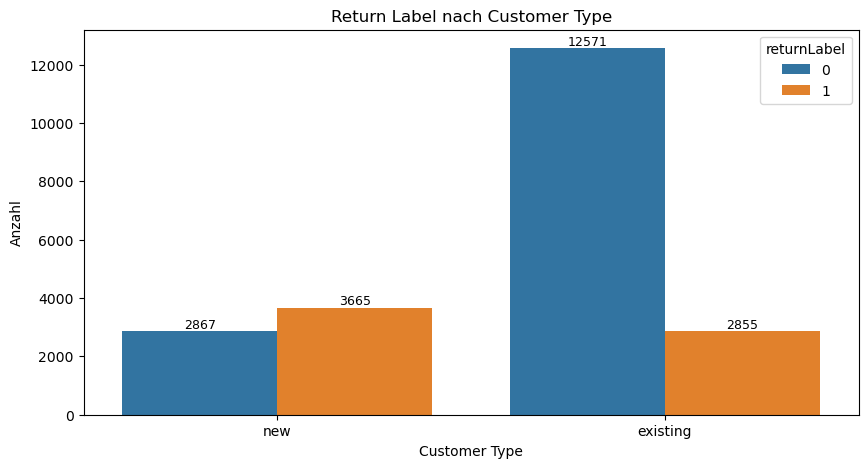

In [9]:
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=train_data, x='customerType', hue='returnLabel')
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
plt.title('Return Label nach Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Anzahl')
plt.show()

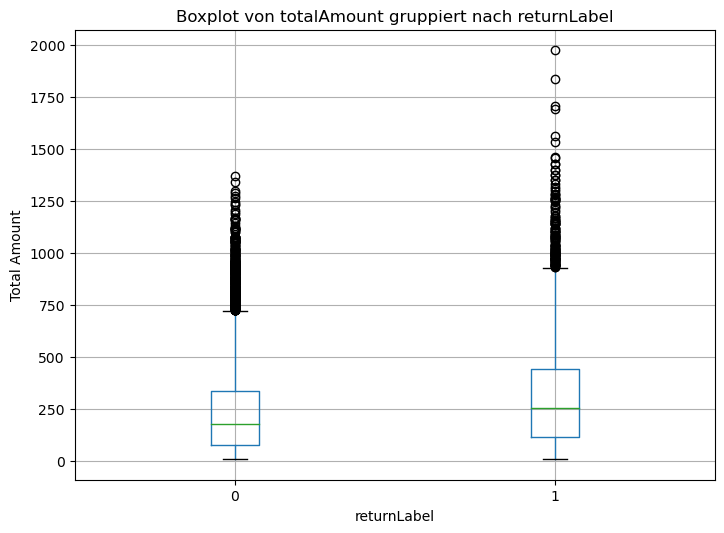

In [21]:
train_data.boxplot(column='totalAmount', by='returnLabel', figsize=(8, 6))
plt.title('Boxplot von totalAmount gruppiert nach returnLabel')
plt.suptitle('')
plt.ylabel('Total Amount')
plt.show()

/Users/user/miniconda3/envs/ml-env/lib/python3.8/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


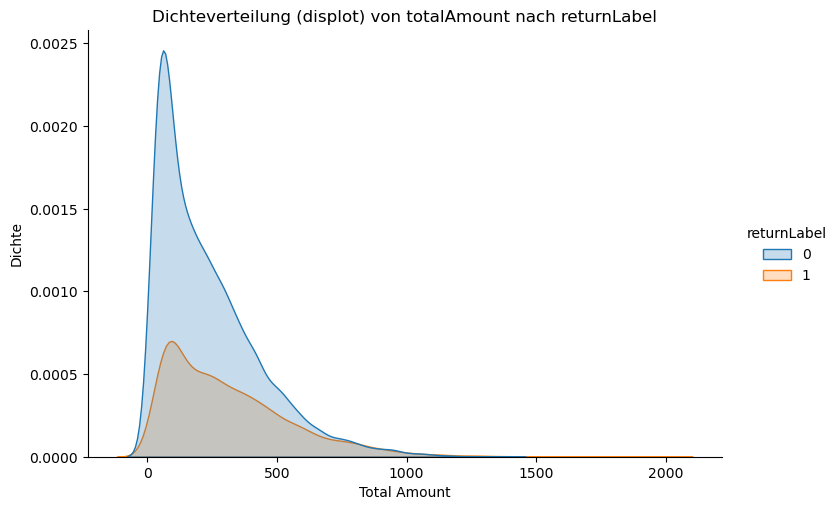

In [22]:
sns.displot(data=train_data, x='totalAmount', hue='returnLabel', kind='kde', fill=True, height=5, aspect=1.5)
plt.title('Dichteverteilung (displot) von totalAmount nach returnLabel')
plt.xlabel('Total Amount')
plt.ylabel('Dichte')
plt.show()

3) Fehldaten auffüllen

In [23]:
train_data.isnull().sum()

transactionId      0
basket             0
customerType     442
totalAmount      477
returnLabel        0
dtype: int64

In [24]:
total_amount_median = train_data['totalAmount'].median()

train_data['totalAmount'] = train_data['totalAmount'].fillna(total_amount_median)

In [25]:
train_data['customerType'].mode()

most_frequent_customer = train_data['customerType'].mode()[0]
train_data['customerType'] = train_data['customerType'].fillna(most_frequent_customer)

4) One-Hot-Encoding

In [26]:
train_data.isnull().sum()

transactionId    0
basket           0
customerType     0
totalAmount      0
returnLabel      0
dtype: int64

In [27]:
customer_dummies = pd.get_dummies(train_data['customerType'], prefix='').astype(int)

customer_dummies.columns = ['existingCustomer', 'newCustomer']

train_data = pd.concat([train_data, customer_dummies], axis=1)

train_data = train_data.drop(columns=['customerType'])

train_data.head()

,transactionId,basket,totalAmount,returnLabel,existingCustomer,newCustomer
0,9534310106,"[4, 3, 4]",252.0,1,0,1
1,7202594767,"[4, 2, 0, 2, 5]",70.0,0,1,0
2,2737331698,[5],84.0,0,1,0
3,4868011733,"[1, 4, 2, 4]",116.0,0,1,0
4,7622406570,"[2, 5, 3, 2, 3, 2, 0]",378.0,0,1,0


5) Neue Features anhand basket

In [28]:
train_data["basket"] = train_data["basket"].apply(lambda x: list(map(int, x.strip("[]").split(","))))

counts = pd.DataFrame(
    train_data["basket"]
        .apply(lambda x: np.bincount(x, minlength=6))
        .tolist(),
    columns=[f"basket_{i}" for i in range(6)]
)

train_data = pd.concat([train_data, counts], axis=1)

In [29]:
train_data.drop("basket", axis=1, inplace=True)
train_data.head()

,transactionId,totalAmount,returnLabel,existingCustomer,newCustomer,basket_0,basket_1,basket_2,basket_3,basket_4,basket_5
0,9534310106,252.0,1,0,1,0,0,0,1,2,0
1,7202594767,70.0,0,1,0,1,0,2,0,1,1
2,2737331698,84.0,0,1,0,0,0,0,0,0,1
3,4868011733,116.0,0,1,0,0,1,1,0,2,0
4,7622406570,378.0,0,1,0,1,0,3,2,0,1


6) Skalieren

In [30]:
scaler = StandardScaler()

features_to_scale = [col for col in train_data.columns if col not in ['transactionId', 'returnLabel']]

train_data[features_to_scale] = scaler.fit_transform(train_data[features_to_scale])

train_data.head()

,transactionId,totalAmount,returnLabel,existingCustomer,newCustomer,basket_0,basket_1,basket_2,basket_3,basket_4,basket_5
0,9534310106,-0.027351,1,-1.558612,1.558612,-0.771563,-0.767737,-0.775046,0.075189,0.634586,-0.644106
1,7202594767,-0.873409,0,0.641597,-0.641597,0.383487,-0.767737,1.514422,-0.880132,-0.122402,0.527090
2,2737331698,-0.808327,0,0.641597,-0.641597,-0.771563,-0.767737,-0.775046,-0.880132,-0.879391,0.527090
3,4868011733,-0.659570,0,0.641597,-0.641597,-0.771563,0.391580,0.369688,-0.880132,0.634586,-0.644106
4,7622406570,0.558381,0,0.641597,-0.641597,0.383487,-0.767737,2.659156,1.030510,-0.879391,0.527090


7) Model trainieren

In [31]:
train_data.head()

,transactionId,totalAmount,returnLabel,existingCustomer,newCustomer,basket_0,basket_1,basket_2,basket_3,basket_4,basket_5
0,9534310106,-0.027351,1,-1.558612,1.558612,-0.771563,-0.767737,-0.775046,0.075189,0.634586,-0.644106
1,7202594767,-0.873409,0,0.641597,-0.641597,0.383487,-0.767737,1.514422,-0.880132,-0.122402,0.527090
2,2737331698,-0.808327,0,0.641597,-0.641597,-0.771563,-0.767737,-0.775046,-0.880132,-0.879391,0.527090
3,4868011733,-0.659570,0,0.641597,-0.641597,-0.771563,0.391580,0.369688,-0.880132,0.634586,-0.644106
4,7622406570,0.558381,0,0.641597,-0.641597,0.383487,-0.767737,2.659156,1.030510,-0.879391,0.527090


In [32]:
train_data.head()
X = train_data.drop(columns=['transactionId', 'returnLabel'])
y = train_data['returnLabel']

print("Starte Logistische Regression...")

lr_model = LogisticRegression(solver='liblinear', random_state=1)
lr_params = {
    'C': [0.1, 1, 4, 5, 6, 10, 30, 100],
    'penalty': ['l1', 'l2']
}
grid_lr = GridSearchCV(lr_model, lr_params, cv=5, scoring='accuracy', n_jobs=-1)
grid_lr.fit(X, y)

print(f"Beste Parameter LR: {grid_lr.best_params_}")
print(f"Beste Genauigkeit LR: {grid_lr.best_score_:.4f}\n")


print("Starte Random Forest...")
rf_model = RandomForestClassifier(random_state=1)
rf_params = {
    'n_estimators': [60, 80, 100, 120, 140],
    'max_depth': [2, 4, 6]
}
grid_rf = GridSearchCV(rf_model, rf_params, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X, y)

print(f"Beste Parameter RF: {grid_rf.best_params_}")
print(f"Beste Genauigkeit RF: {grid_rf.best_score_:.4f}\n")



print("Starte Gradient Boosting...")
gb_model = GradientBoostingClassifier(random_state=1)
gb_params = {
    'n_estimators': [60, 80, 100, 120, 140],
    'max_depth': [2, 4, 6]
}
grid_gb = GridSearchCV(gb_model, gb_params, cv=5, scoring='accuracy', n_jobs=-1)
grid_gb.fit(X, y)

print(f"Beste Parameter GB: {grid_gb.best_params_}")
print(f"Beste Genauigkeit GB: {grid_gb.best_score_:.4f}\n")

Starte Logistische Regression...
Beste Parameter LR: {'C': 100, 'penalty': 'l2'}
Beste Genauigkeit LR: 0.8788

Starte Random Forest...
Beste Parameter RF: {'max_depth': 6, 'n_estimators': 60}
Beste Genauigkeit RF: 0.8688

Starte Gradient Boosting...
Beste Parameter GB: {'max_depth': 4, 'n_estimators': 100}
Beste Genauigkeit GB: 0.8792



8) Testdaten hochladen

In [33]:
test_data = pd.read_csv('test.csv', sep=';')
test_data.head()

,transactionId,basket,customerType,totalAmount,returnLabel
0,4132523932,"[4, 3, 4, 3, 2, 3]",existing,366.0,1
1,8998574539,"[3, 4, 4, 3, 5]",existing,85.0,0
2,9346688547,"[1, 1, 2, 2, 4, 4, 3, 1, 1, 0, 3]",existing,275.0,0
3,4533897707,"[3, 2, 2, 1, 5, 1, 1, 0]",existing,528.0,0
4,3334800500,"[4, 2, 3, 5, 2, 5, 1]",existing,287.0,0


9) Leere Zeilen entfernen

In [34]:
test_data.isnull().sum()

transactionId      0
basket             0
customerType     203
totalAmount      175
returnLabel        0
dtype: int64

In [35]:
test_data.shape

(9600, 5)

In [37]:
test_data.dropna(thresh=5, inplace=True)
test_data.reset_index(drop=True, inplace=True)
counts.reset_index(drop=True, inplace=True)

In [38]:
test_data.shape

(9226, 5)

In [39]:
test_data.isnull().sum()

transactionId    0
basket           0
customerType     0
totalAmount      0
returnLabel      0
dtype: int64

10) Transformation von Daten wie beim train_daten

In [40]:
customer_dummies = pd.get_dummies(test_data['customerType'], prefix='').astype(int)


customer_dummies.columns = ['existingCustomer', 'newCustomer']

test_data = pd.concat([test_data, customer_dummies], axis=1)

test_data = test_data.drop(columns=['customerType'])

test_data.head()

,transactionId,basket,totalAmount,returnLabel,existingCustomer,newCustomer
0,4132523932,"[4, 3, 4, 3, 2, 3]",366.0,1,1,0
1,8998574539,"[3, 4, 4, 3, 5]",85.0,0,1,0
2,9346688547,"[1, 1, 2, 2, 4, 4, 3, 1, 1, 0, 3]",275.0,0,1,0
3,4533897707,"[3, 2, 2, 1, 5, 1, 1, 0]",528.0,0,1,0
4,3334800500,"[4, 2, 3, 5, 2, 5, 1]",287.0,0,1,0


In [41]:
test_data["basket"] = test_data["basket"].apply(lambda x: list(map(int, x.strip("[]").split(","))))

counts = pd.DataFrame(
    test_data["basket"]
    .apply(lambda x: np.bincount(x, minlength=6))
    .tolist(),
    columns=[f"basket_{i}" for i in range(6)]
)

test_data = pd.concat([test_data, counts], axis=1)

test_data.drop("basket", axis=1, inplace=True)

In [42]:
test_data.head()

,transactionId,totalAmount,returnLabel,existingCustomer,newCustomer,basket_0,basket_1,basket_2,basket_3,basket_4,basket_5
0,4132523932,366.0,1,1,0,0,0,1,3,2,0
1,8998574539,85.0,0,1,0,0,0,0,2,2,1
2,9346688547,275.0,0,1,0,1,4,2,2,2,0
3,4533897707,528.0,0,1,0,1,3,2,1,0,1
4,3334800500,287.0,0,1,0,0,1,2,1,1,2


11) Skalieren

In [43]:
scaler = StandardScaler()

features_to_scale = [col for col in test_data.columns if col not in ['transactionId', 'returnLabel']]

test_data[features_to_scale] = scaler.fit_transform(test_data[features_to_scale])

test_data.head()

,transactionId,totalAmount,returnLabel,existingCustomer,newCustomer,basket_0,basket_1,basket_2,basket_3,basket_4,basket_5
0,4132523932,0.462354,1,0.641871,-0.641871,-0.777495,-0.784618,0.392539,1.988715,0.623829,-0.652663
1,8998574539,-0.800293,0,0.641871,-0.641871,-0.777495,-0.784618,-0.771951,1.032747,0.623829,0.525246
2,9346688547,0.053454,0,0.641871,-0.641871,0.387927,3.847529,1.557029,1.032747,0.623829,-0.652663
3,4533897707,1.190286,0,0.641871,-0.641871,0.387927,2.689492,1.557029,0.076780,-0.875570,0.525246
4,3334800500,0.107375,0,0.641871,-0.641871,-0.777495,0.373419,1.557029,0.076780,-0.125871,1.703155


12) Predict mit die 3 Modelle

In [44]:
X_test = test_data[X.columns]
y_test = test_data['returnLabel']

predictions_lr = grid_lr.predict(X_test)
predictions_rf = grid_rf.predict(X_test)
predictions_gb = grid_gb.predict(X_test)
ergebnisse = pd.DataFrame({
    'transactionId': test_data['transactionId'].astype('int64'),
    'Vorhersage_LR': predictions_lr,
    'Vorhersage_RF': predictions_rf,
    'Vorhersage_GB': predictions_gb
})

ergebnisse.head()

,transactionId,Vorhersage_LR,Vorhersage_RF,Vorhersage_GB
0,4132523932,1,1,1
1,8998574539,0,0,0
2,9346688547,0,0,0
3,4533897707,0,0,0
4,3334800500,0,0,0


13) Accuracy, Precison und Recall

In [45]:
modelle = {
    'Logistische Regression': predictions_lr,
    'Random Forest': predictions_rf,
    'Gradient Boosting': predictions_gb
}

for name, preds in modelle.items():
    acc_test = accuracy_score(y_test, preds)
    prec_test = precision_score(y_test, preds)
    rec_test = recall_score(y_test, preds)
    
    print(f"\n{name}:")
    print(f"Accuracy (Test):  {acc_test:.4f}")
    print(f"Precision (Test): {prec_test:.4f}")
    print(f"Recall (Test):    {rec_test:.4f}")



Logistische Regression:
Accuracy (Test):  0.8735
Precision (Test): 0.8101
Recall (Test):    0.7527

Random Forest:
Accuracy (Test):  0.8618
Precision (Test): 0.8010
Recall (Test):    0.7146

Gradient Boosting:
Accuracy (Test):  0.8716
Precision (Test): 0.7993
Recall (Test):    0.7607


14) Accuracy vergleichen

In [46]:
acc_train_lr = accuracy_score(y, grid_lr.predict(X))
acc_train_rf = accuracy_score(y, grid_rf.predict(X))
acc_train_gb = accuracy_score(y, grid_gb.predict(X))

acc_test_lr = accuracy_score(y_test, predictions_lr)
acc_test_rf = accuracy_score(y_test, predictions_rf)
acc_test_gb = accuracy_score(y_test, predictions_gb)

vergleichs_daten = {
    'Logistische Regression': (acc_train_lr, acc_test_lr),
    'Random Forest': (acc_train_rf, acc_test_rf),
    'Gradient Boosting': (acc_train_gb, acc_test_gb)
}

for name, (train_acc, test_acc) in vergleichs_daten.items():
    diff = (train_acc - test_acc) * 100
    print(f"\n{name}:")
    print(f"Accuracy Training: {train_acc:.4f}")
    print(f"Accuracy Test:     {test_acc:.4f}")
    print(f"Unterschied:       {diff:.2f}%")
    
    if diff > 5:
        print("JA, es liegt Overfitting vor")
    else:
        print("Kein Overfitting.")


Logistische Regression:
Accuracy Training: 0.8784
Accuracy Test:     0.8735
Unterschied:       0.49%
Kein Overfitting.

Random Forest:
Accuracy Training: 0.8710
Accuracy Test:     0.8618
Unterschied:       0.92%
Kein Overfitting.

Gradient Boosting:
Accuracy Training: 0.8849
Accuracy Test:     0.8716
Unterschied:       1.33%
Kein Overfitting.


15) Falsche Klassifizierung

In [47]:
falsch_lr = set(np.where(predictions_lr != y_test)[0])
falsch_rf = set(np.where(predictions_rf != y_test)[0])
falsch_gb = set(np.where(predictions_gb != y_test)[0])

gemeinsame_fehler = falsch_lr.intersection(falsch_rf).intersection(falsch_gb)

print(f"Fehlklassifikationen LR: {len(falsch_lr)} Datenpunkte")
print(f"Fehlklassifikationen RF: {len(falsch_rf)} Datenpunkte")
print(f"Fehlklassifikationen GB: {len(falsch_gb)} Datenpunkte")
print(f"Anzahl der gemeinsam falsch klassifizierten Datenpunkten: {len(gemeinsame_fehler)}")

Fehlklassifikationen LR: 1167 Datenpunkte
Fehlklassifikationen RF: 1275 Datenpunkte
Fehlklassifikationen GB: 1185 Datenpunkte
Anzahl der gemeinsam falsch klassifizierten Datenpunkten: 888


16) Feature-Importance 

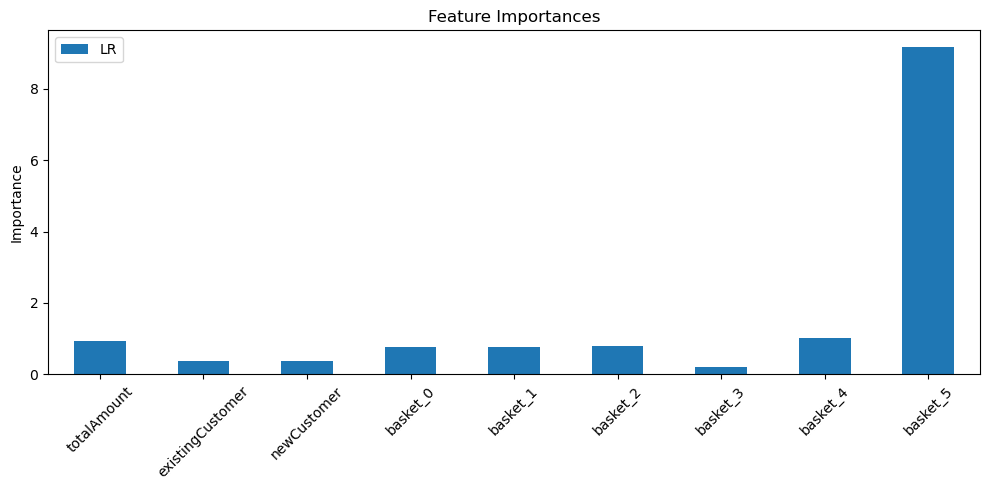

In [51]:
importances = pd.DataFrame({
    'LR': np.abs(grid_lr.best_estimator_.coef_[0]),
    'RF': grid_rf.best_estimator_.feature_importances_,
    'GB': grid_gb.best_estimator_.feature_importances_
}, index=X.columns)

importances.plot(kind='bar', figsize=(10, 5))
plt.title('Feature Importances')
plt.ylabel('Importance')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()